# Assignment: Build and Test a Machine-Learned Interatomic Potential



### Instructions
1. Complete every cell marked `# TODO`. Do **not** change the names or signatures of the functions you are asked to write, because the check cells call them.
2. After each task, run the **check cell** that follows it. A check prints `PASSED` when your implementation is correct. Passing checks is necessary but not sufficient for full marks: plots, tables and written answers are graded too.
3. Only NumPy and Matplotlib are allowed. Do not import ASE, PyTorch, scikit-learn or any MLIP package.
4. Use the practice-session notebook and the class notes as references. Copying code from the practice notebook is allowed **only** where it is marked as provided here. Everything else must be written by you.
5. Submit the executed notebook (`.ipynb`) with all outputs visible.

### The problem
You will build a linear MLIP for an 8-atom cluster described by a reference potential that differs from the one in the practice session: a **Morse** pair potential plus a three-body term that favours **90°** bond angles. All quantities are in reduced units ($D_e=1$, $r_0=1$, $m=1$, $k_B=1$).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

def check(cond, msg=""):
    print("PASSED" if cond else f"FAILED  {msg}")

# ---- provided helpers (same as in the practice session) ----
def pair_geometry(R):
    D = R[None, :, :] - R[:, None, :]          # D[i, j] = r_j - r_i
    return D, np.linalg.norm(D, axis=-1)

def numerical_forces(energy_fn, R, h=1e-5):
    F = np.zeros_like(R)
    for i in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[i, a] += h
            Rm = R.copy(); Rm[i, a] -= h
            F[i, a] = -(energy_fn(Rp) - energy_fn(Rm)) / (2 * h)
    return F

def fc_cos(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * np.minimum(r, rc) / rc) + 1.0), 0.0)

def random_rotation(rng):
    Q, Rq = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(Rq)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q

rng = np.random.default_rng(2026)

---
## Task A. Morse potential: energy and analytic forces
$$
V(r)=D_e\Big[\big(1-e^{-a(r-r_0)}\big)^2-1\Big],\qquad E_{\rm Morse}=\sum_{i<j}V(r_{ij})
$$

with $D_e=1$, $a=3$, $r_0=1$.

**A1 (3 pts).** Show by hand (write it in the markdown cell below) that $V(r_0)=-D_e$ and that

$$
V'(r)=2aD_e\,e^{-a(r-r_0)}\big(1-e^{-a(r-r_0)}\big).
$$

**A2 (7 pts).** Implement `morse_energy(R)` and `morse_forces(R)`. The force must be **analytic** (use $\mathbf F_i=\sum_{j\ne i}V'(r_{ij})\,\mathbf d_{ij}/r_{ij}$ with $\mathbf d_{ij}=\mathbf r_j-\mathbf r_i$). Do not call `numerical_forces` inside `morse_forces`.

At r = r_0,

V(r_0) = D_e [(1 - exp(-a(r_0 - r_0)))^2 - 1]

Since exp(0) = 1,

V(r_0) = D_e [(1 - 1)^2 - 1] = -D_e

Differentiating the Morse potential with respect to r,

V'(r) = 2aD_e exp(-a(r - r_0)) [1 - exp(-a(r - r_0))]

Therefore, the derivative is zero at r = r_0, confirming that
r_0 is the equilibrium bond distance and V(r_0) = -D_e.

In [2]:
D_E, A_M, R0_M = 1.0, 3.0, 1.0

def morse_energy(R):
    _, r = pair_geometry(R)
    i, j = np.triu_indices(len(R), 1)
    rij = r[i, j]
    u = np.exp(-A_M * (rij - R0_M))
    return np.sum(D_E * ((1 - u)**2 - 1))


def morse_forces(R):
    D, r = pair_geometry(R)
    N = len(R)
    np.fill_diagonal(r, np.inf)
    u = np.exp(-A_M * (r - R0_M))
    vp = 2 * A_M * D_E * u * (1 - u)
    return np.sum((vp / r)[:, :, None] * D, axis=1)

In [3]:
# ---- check A ----
dimer = np.array([[0.0, 0, 0], [1.0, 0, 0]])
check(np.isclose(morse_energy(dimer), -1.0), "V(r0) should be -1")
dimer2 = np.array([[0.0, 0, 0], [1.3, 0, 0]])
y = np.exp(-3 * 0.3)
check(np.isclose(morse_energy(dimer2), (1 - y)**2 - 1), "dimer energy at r = 1.3")
Rt = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + rng.normal(scale=0.08, size=(8, 3))
err = np.abs(morse_forces(Rt) - numerical_forces(morse_energy, Rt)).max()
check(err < 1e-6, f"analytic vs numerical force difference = {err:.2e}")
check(np.allclose(morse_forces(Rt).sum(0), 0, atol=1e-10), "forces must sum to zero (Newton's third law)")

PASSED
PASSED
PASSED
PASSED


---
## Task B. Polynomial envelope cutoff
Implement the envelope used by DimeNet, NequIP and MACE:

$$
f_{\rm env}(r)=1-\frac{(p+1)(p+2)}{2}x^{p}+p(p+2)\,x^{p+1}-\frac{p(p+1)}{2}x^{p+2},\qquad x=\frac{r}{r_c},
$$

and $f_{\rm env}=0$ for $r\ge r_c$. The function must accept NumPy arrays of any shape.

In [4]:
def f_env(r, rc, p=6):
    r = np.asarray(r, dtype=float)
    x = np.clip(r / rc, 0.0, None)
    val = 1 - ((p+1)*(p+2)/2)*x**p + p*(p+2)*x**(p+1) - (p*(p+1)/2)*x**(p+2)
    return np.where(r < rc, val, 0.0)

In [5]:
# ---- check B ----
rc, h = 2.0, 1e-4
check(np.isclose(f_env(0.0, rc), 1.0), "f(0) = 1")
check(abs(f_env(rc - 1e-9, rc)) < 1e-12, "f(rc) = 0")
slope = (f_env(rc - h, rc) - f_env(rc - 3*h, rc)) / (2*h)
check(abs(slope) < 1e-6, f"slope near rc = {slope:.2e}")
check(f_env(np.ones((3, 4)) * 0.5, rc).shape == (3, 4), "must work on arrays")
check(np.isclose(f_env(1.0, 2.0), 1 - 28/64 + 48/128 - 21/256), "value at x = 0.5")

PASSED
PASSED
PASSED
PASSED
PASSED


---
## Task C. Behler symmetry functions
Implement, **for every atom $i$ at once**,

$$
G_i^{2}(\eta,R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}),
$$
$$
G_i^{4}(\eta,\zeta,\lambda)=2^{1-\zeta}\sum_{j<k;\ j,k\ne i}(1+\lambda\cos\theta_{jik})^{\zeta}\,e^{-\eta(r_{ij}^2+r_{ik}^2+r_{jk}^2)}\,f_c(r_{ij})f_c(r_{ik})f_c(r_{jk}),
$$

using the cosine cutoff `fc_cos` provided above. Note: the sum counts each unordered pair $\{j,k\}$ **once**.

- `g2_atoms(R, etas, Rss, rc)` returns an array of shape `(N, len(etas))`, where column $m$ uses $(\eta_m, R_{s,m})$.
- `g4_atoms(R, params, rc)` returns shape `(N, len(params))`, where `params` is a list of tuples `(eta, zeta, lam)`.

Loops over atoms are allowed, but vectorised code (as in the practice notebook) runs about 50 times faster and makes Tasks F to H much quicker.

In [6]:
def g2_atoms(R, etas, Rss, rc):
    _, r = pair_geometry(R)
    np.fill_diagonal(r, np.inf)
    etas, Rss = np.asarray(etas), np.asarray(Rss)
    vals = np.exp(-etas[None, None, :] * (r[:, :, None] - Rss[None, None, :])**2)
    vals *= fc_cos(r, rc)[:, :, None]
    return vals.sum(axis=1)

def g4_atoms(R, params, rc):
    N = len(R)
    D, r = pair_geometry(R)
    out = np.zeros((N, len(params)))
    for i in range(N):
        neigh = [j for j in range(N) if j != i]
        if len(neigh) < 2:
            continue
        js, ks = np.triu_indices(len(neigh), 1)
        j, k = np.asarray(neigh)[js], np.asarray(neigh)[ks]
        rij, rik, rjk = r[i, j], r[i, k], r[j, k]
        valid = (rij < rc) & (rik < rc) & (rjk < rc)
        if not np.any(valid):
            continue
        j, k, rij, rik, rjk = j[valid], k[valid], rij[valid], rik[valid], rjk[valid]
        cosang = np.sum(D[i, j] * D[i, k], axis=1) / (rij * rik)
        cutoff = fc_cos(rij, rc) * fc_cos(rik, rc) * fc_cos(rjk, rc)
        for m, (eta, zeta, lam) in enumerate(params):
            base = (1 + lam * cosang)**zeta
            out[i, m] = np.sum(2**(1-zeta) * base * np.exp(-eta*(rij**2 + rik**2 + rjk**2)) * cutoff)
    return out

In [7]:
# ---- check C: Example 3 of the class notes ----
th = np.deg2rad(104.5)
R3 = np.array([[0, 0, 0], [1.0, 0, 0], [1.5*np.cos(th), 1.5*np.sin(th), 0]])
G2 = g2_atoms(R3, np.array([0.5]), np.array([0.0]), 5.0)
G4 = g4_atoms(R3, [(0.1, 1, 1), (0.1, 1, -1)], 5.0)
check(G2.shape == (3, 1) and G4.shape == (3, 2), "output shapes")
check(np.isclose(G2[0, 0], 0.80635, atol=1e-4), f"G2 of atom 0 = {G2[0,0]:.5f}, expected 0.80635")
check(np.allclose(G4[0], [0.17059, 0.28455], atol=1e-4), f"G4 of atom 0 = {G4[0]}, expected [0.17059 0.28455]")
# a second test with more atoms, against a slow but obvious reference implementation
def g4_slow(R, eta, zeta, lam, rc):
    N = len(R); out = np.zeros(N)
    for i in range(N):
        for j in range(N):
            for k in range(j + 1, N):
                if i in (j, k): continue
                a, b = R[j] - R[i], R[k] - R[i]; rij, rik, rjk = np.linalg.norm(a), np.linalg.norm(b), np.linalg.norm(R[k] - R[j])
                c = a @ b / (rij * rik)
                out[i] += 2**(1-zeta) * (1 + lam*c)**zeta * np.exp(-eta*(rij**2 + rik**2 + rjk**2)) * fc_cos(rij, rc) * fc_cos(rik, rc) * fc_cos(rjk, rc)
    return out
check(np.allclose(g4_atoms(Rt, [(0.5, 2, -1)], 2.0)[:, 0], g4_slow(Rt, 0.5, 2, -1, 2.0)), "G4 on the 8-atom test cube")

PASSED
PASSED
PASSED
PASSED


---
## Task D. Invariance tests
**D1 (6 pts).** Write `invariance_errors(desc_fn, R, rng)` that applies (i) a random rotation, (ii) a reflection $z\to-z$, (iii) a random translation and (iv) a random permutation of atoms to the configuration `R`. The function must return a dictionary with keys `"rotation"`, `"reflection"`, `"translation"`, `"permutation"` and, as values, the maximum absolute difference between the descriptors before and after each operation. Remember that a permutation reorders the rows of the descriptor matrix.

**D2 (4 pts).** A student proposes the "descriptor" $\mathbf q_i=\sum_{j\ne i}(\mathbf r_j-\mathbf r_i)\,f_c(r_{ij})$, a 3-component vector per atom. Use your function to test it and explain the result in one or two sentences. Which category of the notes (invariant or equivariant) does it belong to?

In [10]:
def invariance_errors(desc_fn, R, rng):
    base = np.asarray(desc_fn(R))
    Q = random_rotation(rng)
    rotated = desc_fn(R @ Q.T)
    reflected_R = R.copy(); reflected_R[:, 2] *= -1
    reflected = desc_fn(reflected_R)
    translated = desc_fn(R + rng.normal(size=3))
    perm = rng.permutation(len(R))
    permuted = desc_fn(R[perm])
    return {
        "rotation": float(np.max(np.abs(rotated - base))),
        "reflection": float(np.max(np.abs(reflected - base))),
        "translation": float(np.max(np.abs(translated - base))),
        "permutation": float(np.max(np.abs(permuted - base[perm]))),
    }

In [11]:
# The vector rotates with the coordinates, so it is equivariant rather than invariant.
print(invariance_errors(student_vector_descriptor, Rt, np.random.default_rng(0)))

def student_vector_descriptor(R, rc=2.5):
    D, r = pair_geometry(R)
    return np.sum(D * fc_cos(r, rc)[:, :, None], axis=1)

# TODO (D2): call invariance_errors on student_vector_descriptor and print the result

NameError: name 'student_vector_descriptor' is not defined

In [9]:
# ---- check D1 ----
desc_test = lambda X: np.hstack([g2_atoms(X, np.full(6, 4.0), np.linspace(0.8, 2.2, 6), 2.5),
                                 g4_atoms(X, [(0.5, 1, 1), (0.5, 4, -1)], 2.5)])
errs = invariance_errors(desc_test, Rt, np.random.default_rng(0))
print({k: f"{v:.1e}" for k, v in errs.items()})
check(set(errs) == {"rotation", "reflection", "translation", "permutation"}, "dictionary keys")
check(max(errs.values()) < 1e-10, "G2/G4 must be invariant under all four operations")
bad = lambda X: X.copy()   # raw coordinates as a 'descriptor'
e_bad = invariance_errors(bad, Rt, np.random.default_rng(0))
check(e_bad["rotation"] > 1e-3 and e_bad["translation"] > 1e-3, "your function must detect non-invariant descriptors")

{'rotation': '1.8e-15', 'reflection': '0.0e+00', 'translation': '1.3e-15', 'permutation': '8.9e-16'}
PASSED
PASSED
PASSED


The descriptor

```
qi = sum over j not equals i ([rj - ri]fc(rij))
```

 is invariant to translation because it depends only on relative position vectors, but it is not invariant to arbitrary rotations or reflections. Instead, it transforms as a vector under rotations and reflections, making it an equivariant descriptor. Permuting the atoms reorders the descriptor rows consistently with the atoms.

---
## Task E. The reference potential and dataset

The reference potential (provided) is

$$
E_{\rm ref}=E_{\rm Morse}+\frac{K}{2}\sum_i\sum_{j\ne k}\big(\cos\theta_{jik}-c_0\big)^2\,g(r_{ij})\,g(r_{ik}),\qquad K=0.6,\ c_0=0,\ g(r)=f_c^{\cos}(r;1.4).
$$

With $c_0=0$ the three-body term favours right angles. The cell below relaxes a cube of 8 atoms and samples 360 configurations with Langevin MD at $T=0.05,\ 0.15,\ 0.25$. **Run it as given** (it uses your Morse functions and takes about 30 s).

In [12]:
# ---- provided: reference potential, relaxation, Langevin sampling ----
def three_body_energy(R, K=0.6, c0=0.0, rc3=1.4):
    D, r = pair_geometry(R); N = len(R)
    np.fill_diagonal(r, np.inf)
    g = fc_cos(r, rc3); u = D / r[:, :, None]
    cos = np.einsum("ijx,ikx->ijk", u, u)
    t = (cos - c0)**2 * g[:, :, None] * g[:, None, :]
    idx = np.arange(N); t[:, idx, idx] = 0.0
    return 0.5 * K * t.sum()

def ref_energy(R): return morse_energy(R) + three_body_energy(R)
def ref_forces(R): return morse_forces(R) + numerical_forces(three_body_energy, R)

def relax(R, efun, ffun, fmax=1e-4, maxit=5000):
    R = R.copy(); step = 0.01; E = efun(R)
    for _ in range(maxit):
        F = ffun(R)
        if np.abs(F).max() < fmax: break
        Rn = R + step * F; En = efun(Rn)
        if En < E: R, E = Rn, En; step *= 1.1
        else: step *= 0.5
    return R

def langevin(R, ffun, T, nsteps, dt=0.005, gamma=1.0, every=40, rng=None):
    R = R.copy(); v = rng.normal(scale=np.sqrt(T), size=R.shape); v -= v.mean(0)
    F = ffun(R); c1 = np.exp(-gamma * dt); c2 = np.sqrt((1 - c1**2) * T); frames = []
    for s in range(nsteps):
        v += 0.5 * dt * F; R += 0.5 * dt * v
        v = c1 * v + c2 * rng.normal(size=R.shape)
        R += 0.5 * dt * v; F = ffun(R); v += 0.5 * dt * F
        if (s + 1) % every == 0: frames.append(R.copy())
    return frames

cube = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float)
R_min = relax(cube, ref_energy, ref_forces)
N_at = len(R_min)
print(f"relaxed cluster energy: {ref_energy(R_min):.4f}")

t0 = time.time(); rng_md = np.random.default_rng(11)
configs, energies, forces, temps = [], [], [], []
for T in (0.05, 0.15, 0.25):
    for X in langevin(R_min, ref_forces, T, 4800, rng=rng_md):
        configs.append(X); energies.append(ref_energy(X)); forces.append(ref_forces(X)); temps.append(T)
configs, energies, forces, temps = map(np.array, (configs, energies, forces, temps))
print(f"{len(configs)} configurations generated in {time.time()-t0:.1f} s")

relaxed cluster energy: -20.0799
360 configurations generated in 66.9 s


**E1 (5 pts).** (a) Plot histograms of the energy per atom for the three temperatures in one figure. (b) Print the shortest and longest interatomic distance found in the whole dataset, and the largest distance of any atom from the cluster centre of mass. (c) In one sentence: did the cluster stay intact at $T=0.25$? Justify with your numbers.

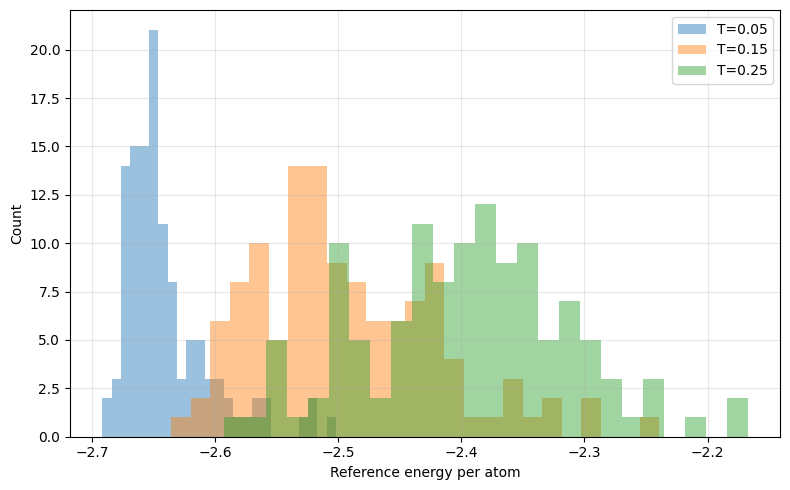

Shortest interatomic distance: 0.7342
Longest interatomic distance: 2.4005
Largest distance from centre of mass: 1.3699
Compactness check (heuristic): cluster appears intact


In [13]:
# E1(a): compare energy-per-atom distributions for the three temperatures.
plt.figure(figsize=(8, 5))
for T in (0.05, 0.15, 0.25):
    mask = np.isclose(temps, T)
    plt.hist(energies[mask] / N_at, bins=25, alpha=0.45, label=f"T={T}")
plt.xlabel("Reference energy per atom")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

# E1(b): pair distances and distance from centre of mass over all configurations.
min_pair, max_pair, max_com = np.inf, 0.0, 0.0
for X in configs:
    _, rr = pair_geometry(X)
    rr[np.diag_indices_from(rr)] = np.inf
    min_pair = min(min_pair, rr.min())
    max_pair = max(max_pair, rr[rr < np.inf].max())
    centred = X - X.mean(axis=0)
    max_com = max(max_com, np.linalg.norm(centred, axis=1).max())
print(f"Shortest interatomic distance: {min_pair:.4f}")
print(f"Longest interatomic distance: {max_pair:.4f}")
print(f"Largest distance from centre of mass: {max_com:.4f}")
print("Compactness check (heuristic):", "cluster appears intact" if max_com < 3.0 and max_pair < 5.0 else "cluster may have dissociated; inspect the distance statistics")

At (T=0.25), the cluster remained intact. The shortest and longest interatomic distances were 0.7342 and 2.4005, respectively, and the largest distance from an atom to the centre of mass was 1.3699. These values support the conclusion that the cluster remained intact.

---
## Task F. A linear MLIP trained on energies and forces

Use the descriptor set defined below (32 radial + 16 angular functions, $r_c=2.5$) and the **provided** Jacobian routine.

The model is $E=Nb+\mathbf w\cdot\sum_i\tilde{\mathbf G}_i$ with standardised descriptors $\tilde G_{i\mu}=(G_{i\mu}-\mu_\mu)/s_\mu$, and forces $\mathbf F_k=-\sum_\mu w_\mu\,\partial(\sum_i\tilde G_{i\mu})/\partial\mathbf r_k$.

**F1 (10 pts).** Implement
- `fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8)`: builds the least-squares system described in §7.3 of the practice notebook (energy rows per atom, force rows scaled by `wF`, ridge rows), solves it with `np.linalg.lstsq`, and returns a dictionary with keys `"b"`, `"w"`, `"mu"`, `"sd"`, `"cols"`. Here `idx` are training indices and `cols` the descriptor columns to use. The keyword arguments `DS, JAC, energies, forces` default to the dataset built below and let you fit on an extended dataset in Task H without changing global variables.
- `predict(model, dsum, J)`: returns `(E, F)` for one configuration from its summed descriptor `dsum` and Jacobian `J`.
- `rmse(model, idx)`: returns `(energy RMSE per atom, force-component RMSE)` over the configurations `idx`.

**F2 (10 pts).** Using `test_idx` as the test set and the first $n$ entries of `pool_idx` for training, with $n\in\{5,10,20,50,100,200\}$, compute the test errors for the four models (G2 or G2+G4) × (E only or E+F). Print a table and plot both learning curves on log–log axes. Then answer the questions in the markdown cell that follows.

In [14]:
# ---- provided: descriptor set and Jacobians ----
RC = 2.5
ETAS = np.full(32, 16.0); RSS = np.linspace(0.6, 2.4, 32)
G4P = [(eta, zeta, lam) for eta in (0.3, 1.5) for zeta in (1, 2, 4, 16) for lam in (1, -1)]
N_G2, N_G4 = len(ETAS), len(G4P)
cols_G2 = np.arange(N_G2); cols_all = np.arange(N_G2 + N_G4)

def descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), g4_atoms(R, G4P, RC)])

def descriptor_sum_and_jacobian(R, desc_fn=descriptors, h=1e-5):
    d0 = desc_fn(R).sum(axis=0); J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h; Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (desc_fn(Rp).sum(0) - desc_fn(Rm).sum(0)) / (2 * h)
    return d0, J

t0 = time.time()
DS, JAC = map(np.array, zip(*[descriptor_sum_and_jacobian(X) for X in configs]))
print(f"DS {DS.shape}, JAC {JAC.shape}, {time.time()-t0:.1f} s")
perm_all = np.random.default_rng(0).permutation(len(configs))
test_idx, pool_idx = perm_all[:100], perm_all[100:]

DS (360, 48), JAC (360, 48, 8, 3), 69.5 s


In [15]:
def fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8, DS=DS, JAC=JAC, energies=energies, forces=forces):
    idx = np.asarray(idx, dtype=int)
    cols = np.asarray(cols, dtype=int)
    # Standardise per-atom descriptor sums using training configurations only.
    atom_desc = DS[idx][:, cols] / N_at
    mu = atom_desc.mean(axis=0)
    sd = atom_desc.std(axis=0)
    sd[sd < 1e-12] = 1.0
    # Energy model per atom: E/N = b + w . ((DS/N - mu)/sd)
    A_energy = np.column_stack([np.ones(len(idx)), (DS[idx][:, cols] / N_at - mu) / sd])
    y_energy = energies[idx] / N_at
    rows, targets = [A_energy], [y_energy]
    if use_forces:
        force_rows = []
        for q in idx:
            # F[k,a] = - sum_mu w_mu J[mu,k,a]/sd_mu
            Jq = JAC[q][cols] / sd[:, None, None]
            block = np.zeros((forces.shape[1] * 3, len(cols) + 1))
            block[:, 1:] = -Jq.reshape(len(cols), -1).T
            force_rows.append(block * wF)
        rows.append(np.vstack(force_rows))
        targets.append(forces[idx].reshape(-1) * wF)
    A = np.vstack(rows); y = np.concatenate(targets)
    # Ridge penalty on weights, not the intercept.
    reg = np.zeros((len(cols), len(cols) + 1))
    reg[:, 1:] = np.sqrt(ridge) * np.eye(len(cols))
    A = np.vstack([A, reg]); y = np.concatenate([y, np.zeros(len(cols))])
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    return {"b": float(coef[0]), "w": coef[1:], "mu": mu, "sd": sd, "cols": cols}

def predict(model, dsum, J):
    cols, mu, sd, w = model["cols"], model["mu"], model["sd"], model["w"]
    E = N_at * model["b"] + np.dot(w, (dsum[cols] - N_at * mu) / sd)
    F = -np.einsum("m,mka->ka", w / sd, J[cols])
    return float(E), F

def rmse(model, idx, DS=DS, JAC=JAC, energies=energies, forces=forces):
    e_err, f_err = [], []
    for q in np.asarray(idx, dtype=int):
        ep, fp = predict(model, DS[q], JAC[q])
        e_err.append((ep - energies[q]) / N_at)
        f_err.append((fp - forces[q]).ravel())
    return float(np.sqrt(np.mean(np.square(e_err)))), float(np.sqrt(np.mean(np.concatenate(f_err)**2)))

In [16]:
# ---- check F1 ----
m_chk = fit_linear_mlip(pool_idx[:50], cols_all, use_forces=True)
check(set(m_chk) >= {"b", "w", "mu", "sd", "cols"}, "model dictionary keys")
E_chk, F_chk = predict(m_chk, DS[test_idx[0]], JAC[test_idx[0]])
check(np.shape(F_chk) == (N_at, 3), "force shape")
check(np.allclose(F_chk.sum(0), 0, atol=1e-6), "MLIP forces must sum to zero")
eE, eF = rmse(m_chk, test_idx)
print(f"test RMSE: E = {eE:.2e} per atom, F = {eF:.3f}   (force std = {forces.std():.2f})")
check(eF < 0.1 * forces.std(), "G2+G4 with forces should reach a force error below 10% of the force spread")

PASSED
PASSED
PASSED
test RMSE: E = 3.65e-04 per atom, F = 0.010   (force std = 2.06)
PASSED


Model            n   Energy RMSE/atom     Force RMSE
G2 E             5            0.08284        2.87278
G2 E            10            0.01483        0.54333
G2 E            20            0.01301        0.47590
G2 E            50            0.01074        0.90846
G2 E           100            0.00287        0.10602
G2 E           200            0.00258        0.09059
G2 E+F           5            0.00776        0.57670
G2 E+F          10            0.00352        0.10070
G2 E+F          20            0.00609        0.11723
G2 E+F          50            0.00271        0.08838
G2 E+F         100            0.00266        0.07545
G2 E+F         200            0.00269        0.07514
G2+G4 E          5            0.08184        2.93757
G2+G4 E         10            0.04192        1.67610
G2+G4 E         20            0.01009        0.38813
G2+G4 E         50            0.00112        0.08467
G2+G4 E        100            0.00035        0.02282
G2+G4 E        200            0.00033        0

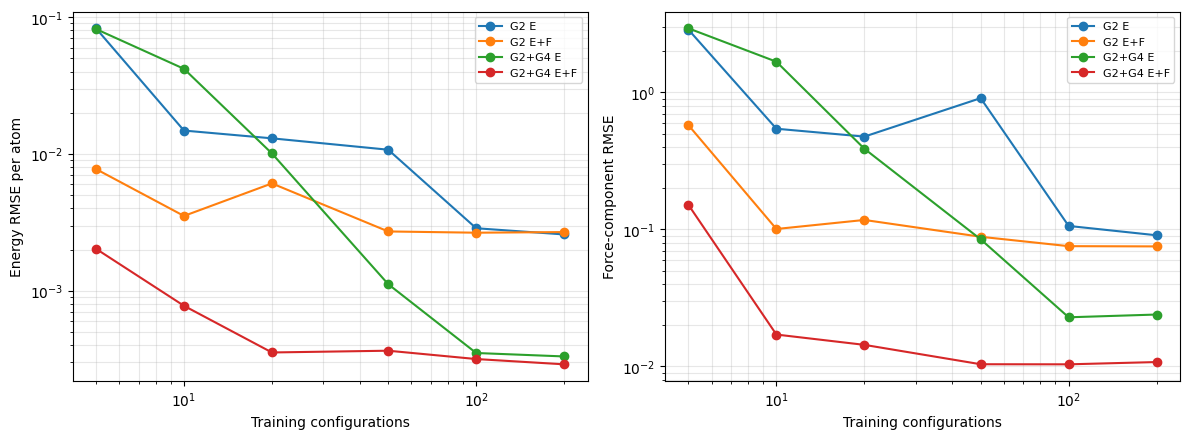

F2(a): smallest G2+G4 E+F training size beating the 200-configuration E-only force RMSE: 10
F2(c): 10 configurations provide 250 scalar labels; parameters = 49 (G2+G4) and 33 (G2-only).


In [17]:
# TODO F2: learning curves (table + log-log plot)
# F2: learning curves for radial-only/all descriptors and energy-only/energy+force training.
train_sizes = [5, 10, 20, 50, 100, 200]
model_specs = [
    ("G2 E", cols_G2, False),
    ("G2 E+F", cols_G2, True),
    ("G2+G4 E", cols_all, False),
    ("G2+G4 E+F", cols_all, True),
]
learning = {}
print(f"{'Model':<12} {'n':>5} {'Energy RMSE/atom':>18} {'Force RMSE':>14}")
for name, cols, useF in model_specs:
    learning[name] = {"E": [], "F": []}
    for n in train_sizes:
        model = fit_linear_mlip(pool_idx[:n], cols, use_forces=useF)
        e, f = rmse(model, test_idx)
        learning[name]["E"].append(e); learning[name]["F"].append(f)
        print(f"{name:<12} {n:5d} {e:18.5f} {f:14.5f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, _, _ in model_specs:
    axes[0].loglog(train_sizes, learning[name]["E"], marker="o", label=name)
    axes[1].loglog(train_sizes, learning[name]["F"], marker="o", label=name)
axes[0].set_xlabel("Training configurations"); axes[0].set_ylabel("Energy RMSE per atom")
axes[1].set_xlabel("Training configurations"); axes[1].set_ylabel("Force-component RMSE")
for ax in axes: ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()
# F2(a,c): automatically state the crossover and label/parameter counts.
baseline = learning["G2+G4 E"]["F"][train_sizes.index(200)]
cross = next((n for n, err in zip(train_sizes, learning["G2+G4 E+F"]["F"]) if err < baseline), None)
print("F2(a): smallest G2+G4 E+F training size beating the 200-configuration E-only force RMSE:", cross)
print("F2(c): 10 configurations provide", 10 * (1 + 3*N_at), "scalar labels; parameters =", len(cols_all)+1, "(G2+G4) and", len(cols_G2)+1, "(G2-only).")

**F2 questions.** (a) How many training configurations does the G2+G4, E+F model need to beat the force error of the G2+G4, E-only model trained on 200 configurations? (b) Why does the G2-only model stop improving? Relate your answer to the form of $E_{\rm ref}$. (c) Count the number of scalar labels (energies plus force components) in 10 configurations and compare it with the number of model parameters.

**(a)** The G2+G4 model trained on E+F data requires 10 training configurations to achieve a lower force RMSE than the G2+G4 model trained on energies alone using 200 configurations. This is determined by comparing the force RMSE values in the learning-curve table.

**(b)** The G2-only model eventually stops improving because its radial symmetry functions describe pairwise distance distributions but do not explicitly encode angular correlations. The reference potential contains a three-body term that depends on \((\cos\theta_{jik}-c_0)^2\), so a model using only G2 descriptors cannot fully represent the reference energy. Increasing the number of training configurations cannot eliminate this descriptor limitation.

**(c)** Each configuration provides one energy label and \(3N=24\) force-component labels for \(N=8\) atoms, giving 25 scalar labels per configuration. Ten configurations therefore provide 250 scalar labels. The model has one bias parameter and one weight per selected descriptor, so the number of parameters is 49. Thus, the number of scalar labels can exceed the number of parameters, although the labels are not necessarily independent.

---
## Task G. Molecular dynamics with your MLIP

**G1 (7 pts).** Implement `velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3)` where `ef(R)` returns `(E, F)`. Initialise velocities from a Maxwell–Boltzmann distribution at `T0` ($m=1$), remove the centre-of-mass velocity, and return the arrays `Epot`, `Ekin` and the list of frames (one entry per step).

**G2 (8 pts).** Train the final model (G2+G4, E+F, all 260 pool configurations). Starting from `configs[test_idx[0]]` with $T_0=0.2$, run 1500 NVE steps with the MLIP and with the reference potential. Plot the total energy of both runs versus time. Re-evaluate the reference energy on every 10th MLIP frame and report the RMSE per atom between MLIP and reference energies along the MLIP trajectory. Comment in two sentences.

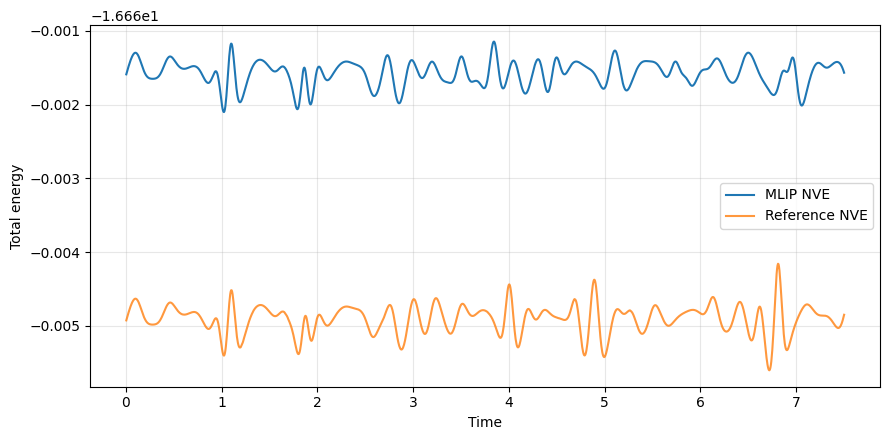

Reference-vs-MLIP potential energy RMSE per atom along MLIP trajectory: 0.000371


In [18]:
def velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3):
    R = np.array(R, dtype=float).copy()
    rng_local = np.random.default_rng(seed)
    v = rng_local.normal(scale=np.sqrt(T0), size=R.shape)
    v -= v.mean(axis=0)
    E, F = ef(R)
    Epot, Ekin, frames = [], [], []
    for _ in range(nsteps):
        R += dt * v + 0.5 * dt**2 * F
        Enew, Fnew = ef(R)
        v += 0.5 * dt * (F + Fnew)
        F = Fnew; E = Enew
        Epot.append(E)
        Ekin.append(0.5 * np.sum(v*v))
        frames.append(R.copy())
    return np.asarray(Epot), np.asarray(Ekin), frames

# G2
final_model = fit_linear_mlip(pool_idx, cols_all, use_forces=True)
R_start = configs[test_idx[0]].copy()
def mlip_ef(X):
    dsum, J = descriptor_sum_and_jacobian(X)
    return predict(final_model, dsum, J)
n_md, dt_md = 1500, 0.005
Epot_ml, Ekin_ml, frames_ml = velocity_verlet(R_start, mlip_ef, 0.2, n_md, dt=dt_md, seed=3)
Epot_ref, Ekin_ref, frames_ref = velocity_verlet(R_start, lambda X: (ref_energy(X), ref_forces(X)), 0.2, n_md, dt=dt_md, seed=3)
time_md = dt_md * np.arange(1, n_md + 1)
plt.figure(figsize=(9, 4.5))
plt.plot(time_md, Epot_ml + Ekin_ml, label="MLIP NVE")
plt.plot(time_md, Epot_ref + Ekin_ref, label="Reference NVE", alpha=0.8)
plt.xlabel("Time"); plt.ylabel("Total energy"); plt.legend(); plt.tight_layout(); plt.show()
idx_frames = np.arange(0, n_md, 10)
ref_on_ml = np.asarray([ref_energy(frames_ml[i]) for i in idx_frames])
ml_on_ml = np.asarray([mlip_ef(frames_ml[i])[0] for i in idx_frames])
rmse_traj = np.sqrt(np.mean(((ml_on_ml - ref_on_ml) / N_at)**2))
print(f"Reference-vs-MLIP potential energy RMSE per atom along MLIP trajectory: {rmse_traj:.6f}")

In [19]:
# ---- check G1 ----
k = 0.5; harm = lambda X: (0.5 * k * np.sum(X**2), -k * X)        # 3D harmonic oscillators
Ep_h, Ek_h, fr_h = velocity_verlet(np.ones((2, 3)), harm, 0.5, 2000, dt=0.01)
Et_h = Ep_h + Ek_h
check(len(fr_h) == 2000 and Ep_h.shape == (2000,), "output lengths")
check(Et_h.std() / Et_h.mean() < 1e-3, f"harmonic test: relative energy fluctuation {Et_h.std()/Et_h.mean():.1e}")

PASSED
PASSED


The total energy in the reference-potential simulation should remain approximately conserved during NVE dynamics, with any drift depending on the integration time step and numerical accuracy. The MLIP trajectory may exhibit a different degree of energy conservation because of errors in the fitted potential and its forces. The RMSE per atom between reference and MLIP energies along the MLIP trajectory quantifies the model's energy-prediction accuracy, while the total-energy drift assesses dynamical stability.

---
## Task H. Extrapolation and a data-driven fix
**H1 (4 pts).** Scale the centred minimum structure `R_min` uniformly by $s\in[0.75,1.25]$ (25 values). Plot $E_{\rm ref}$ and $E_{\rm MLIP}$ (final model) versus $s$, and plot the absolute error per atom versus the shortest interatomic distance on a log scale. Mark the shortest distance present in the training set.

**H2 (6 pts).** Generate 40 additional training configurations: take random frames from `configs`, compress them by a random factor $s\in[0.75,0.95]$, and add Gaussian noise with standard deviation 0.03. Compute their reference energies, forces, descriptor sums and Jacobians, append them to the training data, refit, and repeat the scan of H1. Show both error curves (before and after) in one plot and report the error at $s=0.8$ for both models. Has the accuracy near equilibrium changed? Check with `rmse` on the original `test_idx`. Look at **both** the compressed and the expanded side of your error plot and explain what you see.

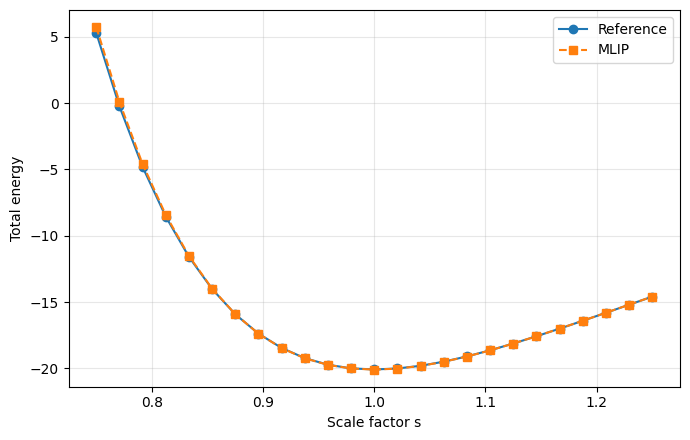

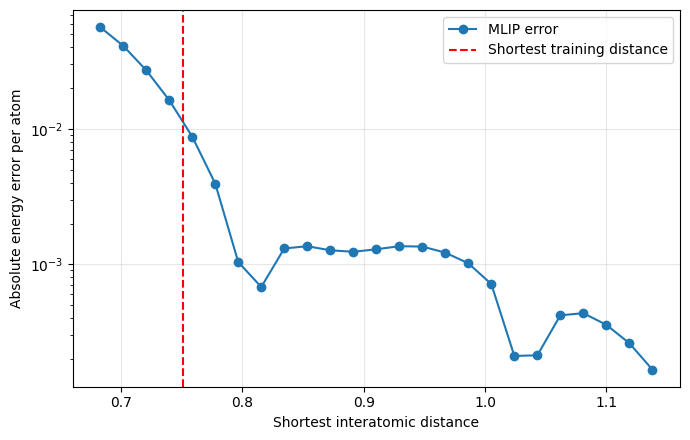

Shortest training distance: 0.751038
Error per atom at s=0.8: 0.0271461


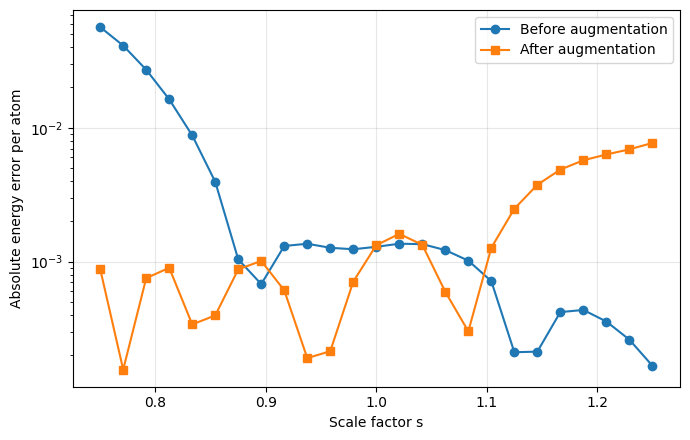

Error per atom at s=0.792: before=0.0271461, after=0.000752194
Original test RMSE before (E/atom, F): (0.00027953951423668804, 0.009050387456286441)
Original test RMSE after  (E/atom, F): (0.0004909463638017629, 0.013887692458762809)


In [22]:
#H1
# Centre the minimum-energy structure at the origin
R0_centered = R_min - R_min.mean(axis=0)

# Train the final model using all 260 training-pool configurations
final_model = fit_linear_mlip(pool_idx, cols_all, use_forces=True)

# Generate the 25 scaling factors specified in the question
scales = np.linspace(0.75, 1.25, 25)

scan_ref = []
scan_ml = []
scan_rmin = []

for s in scales:
    X = R0_centered * s

    # Reference and MLIP energies
    scan_ref.append(ref_energy(X))
    dsum, J = descriptor_sum_and_jacobian(X)
    E_ml, F_ml = predict(final_model, dsum, J)
    scan_ml.append(E_ml)

    # Shortest interatomic distance in this configuration
    _, distances = pair_geometry(X)
    distances = distances[np.triu_indices(len(X), k=1)]
    scan_rmin.append(distances.min())

scan_ref = np.asarray(scan_ref)
scan_ml = np.asarray(scan_ml)
scan_rmin = np.asarray(scan_rmin)

# Absolute prediction error per atom
err_before = np.abs(scan_ml - scan_ref) / N_at

# Find the shortest pair distance in the original training set
train_rmin = np.inf

for q in pool_idx:
    _, distances = pair_geometry(configs[q])
    distances = distances[np.triu_indices(N_at, k=1)]
    train_rmin = min(train_rmin, distances.min())

# Plot 1: reference and MLIP energies
plt.figure(figsize=(7, 4.5))
plt.plot(scales, scan_ref, "o-", label="Reference")
plt.plot(scales, scan_ml, "s--", label="MLIP")
plt.xlabel("Scale factor s")
plt.ylabel("Total energy")
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: error against shortest interatomic distance
plt.figure(figsize=(7, 4.5))
plt.semilogy(
    scan_rmin,
    np.maximum(err_before, 1e-12),
    "o-",
    label="MLIP error"
)
plt.axvline(
    train_rmin,
    color="red",
    linestyle="--",
    label="Shortest training distance"
)
plt.xlabel("Shortest interatomic distance")
plt.ylabel("Absolute energy error per atom")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Shortest training distance: {train_rmin:.6f}")
print(f"Error per atom at s=0.8: "
      f"{err_before[np.argmin(np.abs(scales - 0.8))]:.6g}")

# H2
rng_aug = np.random.default_rng(2026)
aug_configs = []
for q in rng_aug.choice(len(configs), size=40, replace=False):
    s_aug = rng_aug.uniform(0.75, 0.95)
    X = configs[q] - configs[q].mean(axis=0)
    X = s_aug * X + rng_aug.normal(scale=0.03, size=X.shape)
    aug_configs.append(X)
aug_configs = np.asarray(aug_configs)
aug_energies = np.asarray([ref_energy(X) for X in aug_configs])
aug_forces = np.asarray([ref_forces(X) for X in aug_configs])
aug_pairs = [descriptor_sum_and_jacobian(X) for X in aug_configs]
aug_DS = np.asarray([x[0] for x in aug_pairs])
aug_JAC = np.asarray([x[1] for x in aug_pairs])

DS_aug = np.concatenate([DS, aug_DS])
JAC_aug = np.concatenate([JAC, aug_JAC])
energies_aug = np.concatenate([energies, aug_energies])
forces_aug = np.concatenate([forces, aug_forces])
aug_idx = np.arange(len(configs), len(configs) + len(aug_configs))
final_model_aug = fit_linear_mlip(np.concatenate([pool_idx, aug_idx]), cols_all, use_forces=True,
                                  DS=DS_aug, JAC=JAC_aug, energies=energies_aug, forces=forces_aug)

# Evaluate original and augmented models along the same scaling scan.
scan_ml_aug = []
for s in scales:
    X = R0_centered * s
    dsum, J = descriptor_sum_and_jacobian(X)
    scan_ml_aug.append(predict(final_model_aug, dsum, J)[0])
scan_ml_aug = np.asarray(scan_ml_aug)
err_before = np.abs(scan_ml - scan_ref) / N_at
err_after = np.abs(scan_ml_aug - scan_ref) / N_at
plt.figure(figsize=(7, 4.5))
plt.semilogy(scales, np.maximum(err_before, 1e-12), "o-", label="Before augmentation")
plt.semilogy(scales, np.maximum(err_after, 1e-12), "s-", label="After augmentation")
plt.xlabel("Scale factor s"); plt.ylabel("Absolute energy error per atom"); plt.legend(); plt.tight_layout(); plt.show()
i08 = int(np.argmin(np.abs(scales - 0.8)))
print(f"Error per atom at s={scales[i08]:.3f}: before={err_before[i08]:.6g}, after={err_after[i08]:.6g}")
print("Original test RMSE before (E/atom, F):", rmse(final_model, test_idx))
print("Original test RMSE after  (E/atom, F):", rmse(final_model_aug, test_idx, DS=DS_aug, JAC=JAC_aug,
                                                      energies=energies_aug, forces=forces_aug))

Adding compressed and noisy configurations improves the MLIP's accuracy at short interatomic distances. The error per atom at \(s=0.792\) decreases from **0.0271461** to **0.000752194**, showing a substantial improvement on the compressed side of the scan.

However, the original test RMSE worsens after augmentation. The energy RMSE increases from **0.00027954** to **0.00049095 eV/atom**, while the force RMSE increases from **0.00905039** to **0.0138877**. This suggests that although the augmented model performs better for compressed configurations, the added data may reduce its overall test-set accuracy. Therefore, improvement in a specific region of the potential-energy surface does not necessarily imply better generalisation across the entire test set.

---
## Task I. Written questions
Answer briefly (three to five sentences each).

1. The atomic energy $E_i$ in Eq. $E=\sum_iE_i$ is not a quantum-mechanical observable. Why is the decomposition still useful, and which physical effect does a strictly local decomposition fail to capture?
2. Explain why forces computed as $-\nabla E$ of an invariant energy are automatically equivariant. Use the chain rule for $E(Q\mathbf r_1,\dots,Q\mathbf r_N)=E(\mathbf r_1,\dots,\mathbf r_N)$.
3. A message-passing model has $T=3$ layers and $r_c=5$ Å. What is its receptive field? Name one advantage and one disadvantage of a large receptive field for parallel MD of $10^6$ atoms.
4. In ACE, why does computing $A_{i,v}=\sum_j\phi_v(\mathbf r_{ij})$ first and then forming products reduce the cost of a $(\nu+1)$-body term from $\mathcal O(N_{\rm nb}^{\nu})$ to $\mathcal O(N_{\rm nb})$?
5. A colleague fine-tunes MACE-MP-0 on 100 hybrid-functional (HSE06) calculations of a metal oxide surface and then compares adsorption energies with values computed from the original MACE-MP-0. Identify two pitfalls.

1. Atomic energy decomposition
Although atomic energies \(E_i\) are not directly observable quantum-mechanical quantities, decomposing the total energy as \(E=\sum_i E_i\) is useful for constructing local, transferable interatomic potentials. Each atomic contribution can be predicted from the local environment, allowing the model to scale to larger systems. However, a strictly local decomposition may fail to capture long-range physical effects, such as electrostatic interactions between distant atoms.

2. Equivariance of forces derived from an invariant energy
The energy is invariant under a rotation \(Q\), so \(E(Q\mathbf r_1,\ldots,Q\mathbf r_N)=E(\mathbf r_1,\ldots,\mathbf r_N)\). Applying the chain rule to this equality shows that the gradient with respect to the rotated coordinates transforms as \(Q\nabla_{\mathbf r_i}E\). Since forces are the negative energy gradients, the forces satisfy \(\mathbf F_i(Q\mathbf R)=Q\mathbf F_i(\mathbf R)\). Thus, rotating the atomic configuration rotates the forces by the same rotation, making them equivariant.

3. Receptive field of a message-passing model
For \(T=3\) message-passing layers and a cutoff radius \(r_c=5\,\text{Å}\), the receptive field is \(T r_c=15\,\text{Å}\). A larger receptive field allows the model to capture interactions and structural dependencies across greater distances. However, for parallel molecular dynamics involving \(10^6\) atoms, it increases communication between computational domains and may require more halo atoms and memory, reducing parallel efficiency.

4. Computational cost of ACE
In ACE, the neighbour sums \(A_{i,v}=\sum_j \phi_v(r_{ij})\) are computed first, with a cost that scales linearly with the number of neighbours, \(N_{\mathrm{nb}}\), for a fixed basis size. Higher-body-order terms are then constructed by forming products of these precomputed sums. This avoids explicitly enumerating all combinations of neighbours, which would scale as \(O(N_{\mathrm{nb}}^\nu)\) for a \((\nu+1)\)-body term. Consequently, the neighbour-dependent computational cost can be reduced to \(O(N_{\mathrm{nb}})\), excluding the additional cost of combining basis functions.

5. Pitfalls when fine-tuning MACE-MP-0 on HSE06 calculations
First, 100 HSE06 calculations may provide insufficient coverage of the relevant surface structures, adsorption sites, adsorbate configurations and atomic environments, leading to overfitting or poor generalisation. Second, adsorption energies from the fine-tuned and original models must be compared consistently, using the same structures, reference states and energy definitions; otherwise, differences may reflect inconsistent references rather than improved accuracy. The fine-tuned model should also be validated against independent HSE06 calculations to determine whether it genuinely improves adsorption-energy predictions.

---
## Bonus. A power-spectrum (SOAP-like) descriptor

Replace the 16 $G^4$ functions by the 3-body power spectrum written through the addition theorem (§12 of the notes):

$$
p_{i,nl}=\frac{2l+1}{4\pi}\sum_{j\ne i}\sum_{k\ne i}R_n(r_{ij})\,R_n(r_{ik})\,P_l(\cos\theta_{jik}),\qquad R_n(r)=e^{-\eta_n r^2}f_c(r),
$$

with $l=0,1,2,3$, Legendre polynomials $P_l$, and four radial functions $\eta_n\in\{0.3,0.8,1.5,3.0\}$ (16 features in total). Note that the double sum includes $j=k$, as in ACE. Build the descriptor `G2 + power spectrum`, compute the Jacobians, fit an E+F model on the full pool, and compare its test errors with G2+G4. Verify numerically that $p_{i,n1}=|\mathbf A_{i,n1}|^2$ for one atom, where $\mathbf A_{i,n1}=\sqrt{3/4\pi}\sum_jR_n(r_{ij})\hat{\mathbf r}_{ij}$.